BÀI 5a – TRANG 45: KHAI PHÁ LUẬT KẾT HỢP CHO NƯỚC ĐỨC (GERMANY)

Thực hiện lại 12 câu của Bài 2 trang 37–38, thay đổi theo yêu cầu Bài 5a:
- Quốc gia: Germany
- Min Support: 5% (0.05)
- Min Confidence: 50% (0.5)
- Thuật toán: Apriori và FP-Growth
- Dữ liệu: Online Retail.xlsx

Câu 1. Import các thư viện cần thiết và đọc dữ liệu Online Retail

In [1]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

!pip install mlxtend openpyxl -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

print("Phạm Lê Anh Khoa - 6451071035")

with open('data/Online Retail.xlsx', 'rb') as f:
    df = pd.read_excel(f)

df.head(12)


Phạm Lê Anh Khoa - 6451071035


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Xem thông tin dữ liệu

In [2]:
print("Phạm Lê Anh Khoa - 6451071035")
df.info()

Phạm Lê Anh Khoa - 6451071035
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


Câu 2. Tiền xử lý dữ liệu, loại bỏ khoảng trắng và các giá trị thiếu

In [3]:
print("Phạm Lê Anh Khoa - 6451071035")

df['Description'] = df['Description'].str.strip()
df.dropna(subset=['InvoiceNo', 'Description'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

df.head(10)


Phạm Lê Anh Khoa - 6451071035


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Câu 3. Xóa các hóa đơn tín dụng có ký tự 'C' trong InvoiceNo

Xem các hóa đơn tín dụng

In [4]:
print("Phạm Lê Anh Khoa - 6451071035")
df[df['InvoiceNo'].str.contains('C', na=False)].head(10)


Phạm Lê Anh Khoa - 6451071035


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Xóa các hóa đơn tín dụng

In [5]:
print("Phạm Lê Anh Khoa - 6451071035")
df = df[~df['InvoiceNo'].str.contains('C', na=False)].copy()
df.head(10)

Phạm Lê Anh Khoa - 6451071035


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Câu 4. Thống kê số dòng dữ liệu theo từng quốc gia

In [6]:
print("Phạm Lê Anh Khoa - 6451071035")

df['Country'].value_counts()


Phạm Lê Anh Khoa - 6451071035


Country
United Kingdom          486167
Germany                   9042
France                    8408
EIRE                      7894
Spain                     2485
Netherlands               2363
Belgium                   2031
Switzerland               1967
Portugal                  1501
Australia                 1185
Norway                    1072
Italy                      758
Channel Islands            748
Finland                    685
Cyprus                     614
Sweden                     451
Unspecified                446
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     295
Hong Kong                  284
Singapore                  222
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         58


Câu 5. Lọc dữ liệu nước Đức (Germany) và gom nhóm các hóa đơn

In [7]:
print("Phạm Lê Anh Khoa - 6451071035")

df_germany = df[df['Country'] == 'Germany'].copy()

basket = df_germany.groupby(
    ['InvoiceNo', 'Description']
)['Quantity']

df_germany.head(10)


Phạm Lê Anh Khoa - 6451071035


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1109,536527,22809,SET OF 6 T-LIGHTS SANTA,6,2010-12-01 13:04:00,2.95,12662.0,Germany
1110,536527,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,6,2010-12-01 13:04:00,2.55,12662.0,Germany
1111,536527,84945,MULTI COLOUR SILVER T-LIGHT HOLDER,12,2010-12-01 13:04:00,0.85,12662.0,Germany
1112,536527,22242,5 HOOK HANGER MAGIC TOADSTOOL,12,2010-12-01 13:04:00,1.65,12662.0,Germany
1113,536527,22244,3 HOOK HANGER MAGIC GARDEN,12,2010-12-01 13:04:00,1.95,12662.0,Germany
1114,536527,22243,5 HOOK HANGER RED MAGIC TOADSTOOL,12,2010-12-01 13:04:00,1.65,12662.0,Germany
1115,536527,47421,ASSORTED COLOUR LIZARD SUCTION HOOK,24,2010-12-01 13:04:00,0.42,12662.0,Germany
1116,536527,20712,JUMBO BAG WOODLAND ANIMALS,10,2010-12-01 13:04:00,1.95,12662.0,Germany
1117,536527,20713,JUMBO BAG OWLS,10,2010-12-01 13:04:00,1.95,12662.0,Germany
1118,536527,22837,HOT WATER BOTTLE BABUSHKA,4,2010-12-01 13:04:00,4.65,12662.0,Germany


Câu 6. Chuyển đổi dữ liệu về dạng Hot Encoding, với mỗi dòng là một hóa đơn

In [8]:
print("Phạm Lê Anh Khoa - 6451071035")

basket = basket.sum().unstack().reset_index().fillna(0).set_index('InvoiceNo')

basket.head(10)


Phạm Lê Anh Khoa - 6451071035


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537198,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537201,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537212,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Câu 7. Chuyển đổi dữ liệu từ dạng Hot Encoding thành One-hot Encoding

Tạo hàm chuyển đổi dữ liệu

In [9]:
print("Phạm Lê Anh Khoa - 6451071035")

def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    return 1


Phạm Lê Anh Khoa - 6451071035


Áp dụng hàm chuyển đổi

In [10]:
print("Phạm Lê Anh Khoa - 6451071035")
basket = basket.map(encode_data)

basket.head(10)


Phạm Lê Anh Khoa - 6451071035


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537198,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537212,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Câu 8. Xóa thuộc tính POSTAGE

In [11]:
print("Phạm Lê Anh Khoa - 6451071035")

basket.drop('POSTAGE', inplace=True, axis=1, errors='ignore')

basket.head(10)


Phạm Lê Anh Khoa - 6451071035


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537198,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537212,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Câu 9. Áp dụng thuật toán Apriori với min_sup = 5% để tìm tập phổ biến

In [12]:
print("Phạm Lê Anh Khoa - 6451071035")

itemsets = apriori(
    basket.astype(bool),
    min_support=0.05,
    use_colnames=True
)

itemsets.head(10)


Phạm Lê Anh Khoa - 6451071035


,support,itemsets
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
1,0.070022,frozenset({ALARM CLOCK BAKELIKE PINK})
2,0.065646,frozenset({CHARLOTTE BAG APPLES DESIGN})
3,0.050328,frozenset({CHILDRENS CUTLERY DOLLY GIRL})
4,0.061269,frozenset({COFFEE MUG APPLES DESIGN})
5,0.063457,frozenset({FAWN BLUE HOT WATER BOTTLE})
6,0.072210,frozenset({GUMBALL COAT RACK})
7,0.056893,frozenset({IVORY KITCHEN SCALES})
8,0.063457,frozenset({JAM JAR WITH PINK LID})
9,0.091904,frozenset({JAM MAKING SET PRINTED})


Câu 10. Tạo luật kết hợp với min_conf = 50%

Tạo luật kết hợp

In [13]:
print("Phạm Lê Anh Khoa - 6451071035")

rules = association_rules(
    itemsets,
    metric="confidence",
    min_threshold=0.5
)

rules.head(10)


Phạm Lê Anh Khoa - 6451071035


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({PLASTERS IN TIN CIRCUS PARADE}),frozenset({PLASTERS IN TIN WOODLAND ANIMALS}),0.115974,0.137856,0.067834,0.584906,4.242887,1.0,0.051846,2.076984,0.864580,0.364706,0.518533,0.538485
1,frozenset({PLASTERS IN TIN SPACEBOY}),frozenset({PLASTERS IN TIN WOODLAND ANIMALS}),0.107221,0.137856,0.061269,0.571429,4.145125,1.0,0.046488,2.011670,0.849877,0.333333,0.502901,0.507937
2,frozenset({PLASTERS IN TIN WOODLAND ANIMALS}),frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),0.137856,0.245077,0.074398,0.539683,2.202098,1.0,0.040613,1.640006,0.633174,0.241135,0.390246,0.421627
3,frozenset({RED RETROSPOT CHARLOTTE BAG}),frozenset({WOODLAND CHARLOTTE BAG}),0.070022,0.126915,0.059081,0.843750,6.648168,1.0,0.050194,5.587746,0.913551,0.428571,0.821037,0.654634
4,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),frozenset({ROUND SNACK BOXES SET OF 4 FRUITS}),0.245077,0.157549,0.131291,0.535714,3.400298,1.0,0.092679,1.814509,0.935072,0.483871,0.448887,0.684524
5,frozenset({ROUND SNACK BOXES SET OF 4 FRUITS}),frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),0.157549,0.245077,0.131291,0.833333,3.400298,1.0,0.092679,4.529540,0.837922,0.483871,0.779227,0.684524
6,frozenset({SPACEBOY LUNCH BOX}),frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),0.102845,0.245077,0.070022,0.680851,2.778116,1.0,0.044817,2.365427,0.713415,0.251969,0.577243,0.483283
7,frozenset({WOODLAND CHARLOTTE BAG}),frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),0.126915,0.245077,0.063457,0.500000,2.040179,1.0,0.032354,1.509847,0.583960,0.205674,0.337681,0.379464


Xem thông tin tập luật

In [14]:
print("Phạm Lê Anh Khoa - 6451071035")
rules.info()

Phạm Lê Anh Khoa - 6451071035
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         8 non-null      object 
 1   consequents         8 non-null      object 
 2   antecedent support  8 non-null      float64
 3   consequent support  8 non-null      float64
 4   support             8 non-null      float64
 5   confidence          8 non-null      float64
 6   lift                8 non-null      float64
 7   representativity    8 non-null      float64
 8   leverage            8 non-null      float64
 9   conviction          8 non-null      float64
 10  zhangs_metric       8 non-null      float64
 11  jaccard             8 non-null      float64
 12  certainty           8 non-null      float64
 13  kulczynski          8 non-null      float64
dtypes: float64(12), object(2)
memory usage: 1.0+ KB


Chuyển đổi vế trái và vế phải từ frozenset thành chuỗi

In [15]:
print("Phạm Lê Anh Khoa - 6451071035")
rules["antecedents"] = rules["antecedents"].apply(
    lambda x: ', '.join(sorted(x)) if isinstance(x, (frozenset, set)) else str(x)
)

rules["consequents"] = rules["consequents"].apply(
    lambda x: ', '.join(sorted(x)) if isinstance(x, (frozenset, set)) else str(x)
)

rules.head(10)


Phạm Lê Anh Khoa - 6451071035


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,PLASTERS IN TIN CIRCUS PARADE,PLASTERS IN TIN WOODLAND ANIMALS,0.115974,0.137856,0.067834,0.584906,4.242887,1.0,0.051846,2.076984,0.864580,0.364706,0.518533,0.538485
1,PLASTERS IN TIN SPACEBOY,PLASTERS IN TIN WOODLAND ANIMALS,0.107221,0.137856,0.061269,0.571429,4.145125,1.0,0.046488,2.011670,0.849877,0.333333,0.502901,0.507937
2,PLASTERS IN TIN WOODLAND ANIMALS,ROUND SNACK BOXES SET OF4 WOODLAND,0.137856,0.245077,0.074398,0.539683,2.202098,1.0,0.040613,1.640006,0.633174,0.241135,0.390246,0.421627
3,RED RETROSPOT CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.070022,0.126915,0.059081,0.843750,6.648168,1.0,0.050194,5.587746,0.913551,0.428571,0.821037,0.654634
4,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,0.245077,0.157549,0.131291,0.535714,3.400298,1.0,0.092679,1.814509,0.935072,0.483871,0.448887,0.684524
5,ROUND SNACK BOXES SET OF 4 FRUITS,ROUND SNACK BOXES SET OF4 WOODLAND,0.157549,0.245077,0.131291,0.833333,3.400298,1.0,0.092679,4.529540,0.837922,0.483871,0.779227,0.684524
6,SPACEBOY LUNCH BOX,ROUND SNACK BOXES SET OF4 WOODLAND,0.102845,0.245077,0.070022,0.680851,2.778116,1.0,0.044817,2.365427,0.713415,0.251969,0.577243,0.483283
7,WOODLAND CHARLOTTE BAG,ROUND SNACK BOXES SET OF4 WOODLAND,0.126915,0.245077,0.063457,0.500000,2.040179,1.0,0.032354,1.509847,0.583960,0.205674,0.337681,0.379464


In ra các luật đã tìm được





In [16]:
print("Phạm Lê Anh Khoa - 6451071035")

for i in range(len(rules)):
    print(
        rules.iloc[i]['antecedents'], '==>',
        rules.iloc[i]['consequents'],
        '[',
        rules.iloc[i]['support'], ',',
        rules.iloc[i]['confidence'],
        ']'
    )


Phạm Lê Anh Khoa - 6451071035
PLASTERS IN TIN CIRCUS PARADE ==> PLASTERS IN TIN WOODLAND ANIMALS [ 0.06783369803063458 , 0.5849056603773585 ]
PLASTERS IN TIN SPACEBOY ==> PLASTERS IN TIN WOODLAND ANIMALS [ 0.061269146608315096 , 0.5714285714285714 ]
PLASTERS IN TIN WOODLAND ANIMALS ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.07439824945295405 , 0.5396825396825397 ]
RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG [ 0.05908096280087528 , 0.8437500000000001 ]
ROUND SNACK BOXES SET OF4 WOODLAND ==> ROUND SNACK BOXES SET OF 4 FRUITS [ 0.13129102844638948 , 0.5357142857142857 ]
ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.13129102844638948 , 0.8333333333333333 ]
SPACEBOY LUNCH BOX ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.0700218818380744 , 0.6808510638297872 ]
WOODLAND CHARLOTTE BAG ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.06345733041575492 , 0.5 ]


Câu 11. Lấy giá trị độ hỗ trợ và độ tin cậy của tập luật

In [17]:
print("Phạm Lê Anh Khoa - 6451071035")

support = rules['support'].values
confidence = rules['confidence'].values

print("Support:", support)
print("Confidence:", confidence)


Phạm Lê Anh Khoa - 6451071035
Support: [0.0678337  0.06126915 0.07439825 0.05908096 0.13129103 0.13129103
 0.07002188 0.06345733]
Confidence: [0.58490566 0.57142857 0.53968254 0.84375    0.53571429 0.83333333
 0.68085106 0.5       ]


Biểu diễn các thông tin trên biểu đồ

Phạm Lê Anh Khoa - 6451071035


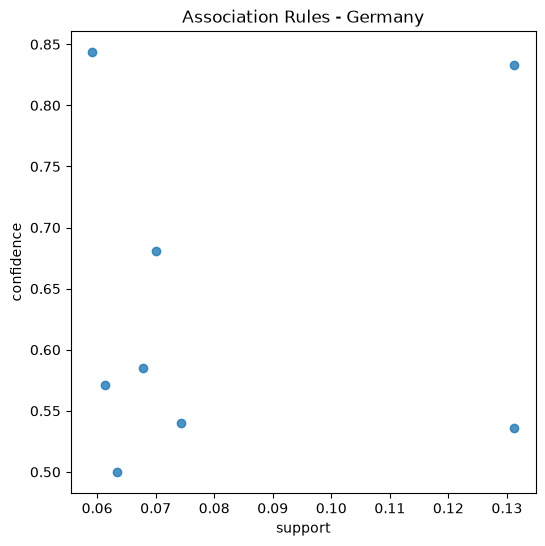

In [18]:
print("Phạm Lê Anh Khoa - 6451071035")
plt.figure(figsize=(6, 6))
plt.title('Association Rules - Germany')
plt.xlabel('support')
plt.ylabel('confidence')

sns.regplot(
    x=support,
    y=confidence,
    fit_reg=False
)

plt.show()


Câu 12. Áp dụng thuật toán FP-Growth với min_sup = 5%

Tìm các tập phổ biến bằng FP-Growth

In [19]:
print("Phạm Lê Anh Khoa - 6451071035")

itemsets_fp = fpgrowth(
    basket.astype(bool),
    min_support=0.05,
    use_colnames=True
)

itemsets_fp.head(10)


Phạm Lê Anh Khoa - 6451071035


,support,itemsets
0,0.100656,frozenset({JUMBO BAG WOODLAND ANIMALS})
1,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
2,0.091904,frozenset({JAM MAKING SET PRINTED})
3,0.085339,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
4,0.063457,frozenset({JAM JAR WITH PINK LID})
5,0.078775,frozenset({JUMBO BAG RED RETROSPOT})
6,0.067834,frozenset({WOODLAND PARTY BAG + STICKER SET})
7,0.056893,frozenset({IVORY KITCHEN SCALES})
8,0.054705,frozenset({MEMO BOARD COTTAGE DESIGN})
9,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})


Tạo luật kết hợp với min_conf = 50%

In [20]:
print("Phạm Lê Anh Khoa - 6451071035")
rules_fp = association_rules(
    itemsets_fp,
    metric="confidence",
    min_threshold=0.5
)

rules_fp.info()


Phạm Lê Anh Khoa - 6451071035
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         8 non-null      object 
 1   consequents         8 non-null      object 
 2   antecedent support  8 non-null      float64
 3   consequent support  8 non-null      float64
 4   support             8 non-null      float64
 5   confidence          8 non-null      float64
 6   lift                8 non-null      float64
 7   representativity    8 non-null      float64
 8   leverage            8 non-null      float64
 9   conviction          8 non-null      float64
 10  zhangs_metric       8 non-null      float64
 11  jaccard             8 non-null      float64
 12  certainty           8 non-null      float64
 13  kulczynski          8 non-null      float64
dtypes: float64(12), object(2)
memory usage: 1.0+ KB


Chuyển đổi vế trái và vế phải thành chuỗi

In [21]:
print("Phạm Lê Anh Khoa - 6451071035")
rules_fp["antecedents"] = rules_fp["antecedents"].apply(
    lambda x: ', '.join(sorted(x)) if isinstance(x, (frozenset, set)) else str(x)
)

rules_fp["consequents"] = rules_fp["consequents"].apply(
    lambda x: ', '.join(sorted(x)) if isinstance(x, (frozenset, set)) else str(x)
)

rules_fp.head(10)


Phạm Lê Anh Khoa - 6451071035


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,0.245077,0.157549,0.131291,0.535714,3.400298,1.0,0.092679,1.814509,0.935072,0.483871,0.448887,0.684524
1,ROUND SNACK BOXES SET OF 4 FRUITS,ROUND SNACK BOXES SET OF4 WOODLAND,0.157549,0.245077,0.131291,0.833333,3.400298,1.0,0.092679,4.529540,0.837922,0.483871,0.779227,0.684524
2,WOODLAND CHARLOTTE BAG,ROUND SNACK BOXES SET OF4 WOODLAND,0.126915,0.245077,0.063457,0.500000,2.040179,1.0,0.032354,1.509847,0.583960,0.205674,0.337681,0.379464
3,PLASTERS IN TIN CIRCUS PARADE,PLASTERS IN TIN WOODLAND ANIMALS,0.115974,0.137856,0.067834,0.584906,4.242887,1.0,0.051846,2.076984,0.864580,0.364706,0.518533,0.538485
4,SPACEBOY LUNCH BOX,ROUND SNACK BOXES SET OF4 WOODLAND,0.102845,0.245077,0.070022,0.680851,2.778116,1.0,0.044817,2.365427,0.713415,0.251969,0.577243,0.483283
5,RED RETROSPOT CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.070022,0.126915,0.059081,0.843750,6.648168,1.0,0.050194,5.587746,0.913551,0.428571,0.821037,0.654634
6,PLASTERS IN TIN WOODLAND ANIMALS,ROUND SNACK BOXES SET OF4 WOODLAND,0.137856,0.245077,0.074398,0.539683,2.202098,1.0,0.040613,1.640006,0.633174,0.241135,0.390246,0.421627
7,PLASTERS IN TIN SPACEBOY,PLASTERS IN TIN WOODLAND ANIMALS,0.107221,0.137856,0.061269,0.571429,4.145125,1.0,0.046488,2.011670,0.849877,0.333333,0.502901,0.507937


In ra các luật kết hợp FP-Growth

In [22]:
print("Phạm Lê Anh Khoa - 6451071035")

for i in range(len(rules_fp)):
    print(
        rules_fp.iloc[i]['antecedents'], '==>',
        rules_fp.iloc[i]['consequents'],
        '[',
        rules_fp.iloc[i]['support'], ',',
        rules_fp.iloc[i]['confidence'],
        ']'
    )


Phạm Lê Anh Khoa - 6451071035
ROUND SNACK BOXES SET OF4 WOODLAND ==> ROUND SNACK BOXES SET OF 4 FRUITS [ 0.13129102844638948 , 0.5357142857142857 ]
ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.13129102844638948 , 0.8333333333333333 ]
WOODLAND CHARLOTTE BAG ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.06345733041575492 , 0.5 ]
PLASTERS IN TIN CIRCUS PARADE ==> PLASTERS IN TIN WOODLAND ANIMALS [ 0.06783369803063458 , 0.5849056603773585 ]
SPACEBOY LUNCH BOX ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.0700218818380744 , 0.6808510638297872 ]
RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG [ 0.05908096280087528 , 0.8437500000000001 ]
PLASTERS IN TIN WOODLAND ANIMALS ==> ROUND SNACK BOXES SET OF4 WOODLAND [ 0.07439824945295405 , 0.5396825396825397 ]
PLASTERS IN TIN SPACEBOY ==> PLASTERS IN TIN WOODLAND ANIMALS [ 0.061269146608315096 , 0.5714285714285714 ]


Vẽ biểu đồ Support và Confidence của FP-Growth

Phạm Lê Anh Khoa - 6451071035


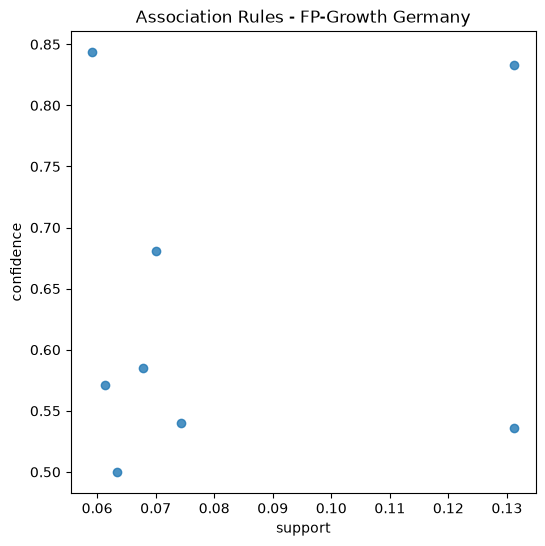

In [23]:
print("Phạm Lê Anh Khoa - 6451071035")
support_fp = rules_fp['support'].values
confidence_fp = rules_fp['confidence'].values

plt.figure(figsize=(6, 6))
plt.title('Association Rules - FP-Growth Germany')
plt.xlabel('support')
plt.ylabel('confidence')

sns.regplot(
    x=support_fp,
    y=confidence_fp,
    fit_reg=False
)

plt.show()
